# Assignment 1 — Working with Open Data

In this assignment you take a **real, public dataset**, ask questions of it, answer them, and document your work so that someone else could reproduce it.

**A few things to know before you start:**
- This course is about **data, not code.** The point of A1 is the analytical questions and what the numbers tell you about how people behave — *not* whether you remember Python syntax.
- You can do the analysis **in Python here, or in Google Sheets.** Every question below works either way. Pick whatever lets you think about the data instead of fighting the tool.
- You may use an **AI assistant** (ChatGPT, Claude, …) to help you write code — with rules. See *A note on using AI* at the bottom before you do.

**What you'll turn in** (committed to your `hcde-410` repo):
1. This notebook, with your answers filled in.
2. A short **README.md** describing your work.
3. A **LICENSE** file, and a note about the dataset's own license.

Your commit history is part of the record — commit as you go.

## Part 0 — Get the data

The data comes from [data.seattle.gov](https://data.seattle.gov/), the City of Seattle's open-data portal. We'll use the [Burke-Gilman Trail counter north of NE 70th St](https://data.seattle.gov/Transportation/Burke-Gilman-Trail-north-of-NE-70th-St-Bicycle-and/2z5v-ecg8), which records **bike and pedestrian traffic, by hour, by direction**.

We'll pull the data straight from the city's API rather than downloading a file by hand. That's a small reproducibility win: anyone who runs this notebook gets the same data the same way, and it's written down exactly where it came from.

In [1]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# The dataset's API endpoint, and a query for one year of data (2019).
# You can paste the full URL into a browser to preview the raw data.
api_endpoint = "https://data.seattle.gov/resource/2z5v-ecg8.json?"
api_parameters = "$limit=50000&$where=date > '2019-01-01T00:00:00' AND date < '2020-01-01T00:00:00'"

response = requests.get(api_endpoint + api_parameters)
raw_data = response.json()
print("Downloaded", len(raw_data), "hourly records.")
# If this cell fails (e.g. the API is down), see the note below the next cell.

Downloaded 8759 hourly records.


Now load it into a **pandas DataFrame** — a table, like a spreadsheet you can compute with.

In [3]:
df = pd.DataFrame(raw_data)
df.head()

,date,bgt_north_of_ne_70th_total,ped_south,ped_north,bike_north,bike_south
0,2019-01-01T01:00:00.000,2,1,0,1,0
1,2019-01-01T02:00:00.000,1,0,0,0,1
2,2019-01-01T03:00:00.000,0,0,0,0,0
3,2019-01-01T04:00:00.000,1,0,0,1,0
4,2019-01-01T05:00:00.000,1,0,0,1,0


### Quick sanity checks

Whenever you work with data **you didn't create**, check that it means what you think before you analyze it. Two things need fixing here:
- the counts arrive as **text**, so we convert them to numbers;
- the `date` is a string, so we convert it to a real **datetime** and pull out the hour and weekday.

We'll also add tidy `bikes` and `peds` columns (north + south).

In [4]:
# convert the count columns from text to numbers
count_cols = ["bike_north", "bike_south", "ped_north", "ped_south", "bgt_north_of_ne_70th_total"]
df[count_cols] = df[count_cols].apply(pd.to_numeric, errors="coerce")

# convert the date string to a real datetime, and derive hour + weekday
df["date"] = pd.to_datetime(df["date"])
df["hour"] = df["date"].dt.hour
df["weekday"] = df["date"].dt.day_name()

# combined bike and pedestrian counts
df["bikes"] = df["bike_north"] + df["bike_south"]
df["peds"]  = df["ped_north"] + df["ped_south"]

df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8759 entries, 0 to 8758
Data columns (total 10 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   date                        8759 non-null   datetime64[ns]
 1   bgt_north_of_ne_70th_total  8759 non-null   int64         
 2   ped_south                   8759 non-null   int64         
 3   ped_north                   8759 non-null   int64         
 4   bike_north                  8759 non-null   int64         
 5   bike_south                  8759 non-null   int64         
 6   hour                        8759 non-null   int32         
 7   weekday                     8759 non-null   object        
 8   bikes                       8759 non-null   int64         
 9   peds                        8759 non-null   int64         
dtypes: datetime64[ns](1), int32(1), int64(7), object(1)
memory usage: 650.2+ KB


,date,bgt_north_of_ne_70th_total,ped_south,ped_north,bike_north,bike_south,hour,bikes,peds
count,8759,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000
mean,2019-07-02 12:00:00,58.423564,8.047380,8.363169,19.875671,22.137344,11.501313,42.013015,16.410549
min,2019-01-01 01:00:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2019-04-02 06:30:00,2.000000,0.000000,0.000000,0.000000,1.000000,6.000000,1.000000,0.000000
50%,2019-07-02 12:00:00,33.000000,5.000000,6.000000,9.000000,8.000000,12.000000,20.000000,11.000000
75%,2019-10-01 17:30:00,91.000000,13.000000,14.000000,31.000000,30.000000,17.500000,64.000000,27.000000
max,2019-12-31 23:00:00,1764.000000,1324.000000,782.000000,199.000000,961.000000,23.000000,1039.000000,1752.000000
std,NaN,73.656910,16.882468,13.164217,26.299728,34.080707,6.921886,56.534598,27.675776


**Look at what `describe()` tells you.** Are there hours with 0 traffic? Any missing values (a sensor can go offline)? Note anything odd — you'll want to mention data limitations later.

**No-code option:** run the next cell to save the cleaned data as a CSV, then open it in Google Sheets and do your analysis there. If you go this route, title your sheet **"A1 — [your name]"**, share it so anyone with the link can view, and paste the link into your written answers.

In [ ]:
df.to_csv("bg_hourly_2019.csv", index=False)
print("Saved bg_hourly_2019.csv — a row per hour of 2019.")

## Part 1 — One worked example: when do cyclists ride?

Here is the whole technique, **once**, so you can see the pattern. After this, the questions are yours.

The move is always the same: **group → summarize → plot → interpret.** In pandas that's a couple of lines (no loops needed).

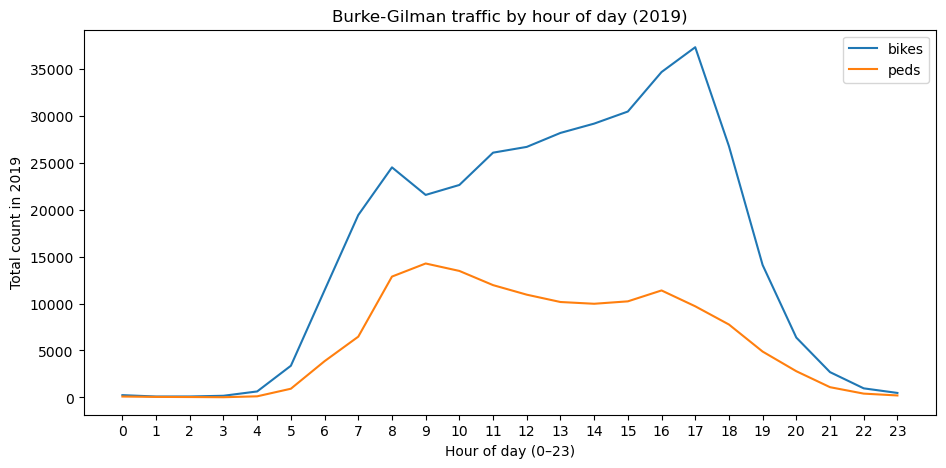

In [5]:
# group every row by its hour of day, and sum bikes and peds within each hour
by_hour = df.groupby("hour")[["bikes", "peds"]].sum()

by_hour.plot(figsize=(11, 5))
plt.title("Burke-Gilman traffic by hour of day (2019)")
plt.xlabel("Hour of day (0–23)")
plt.ylabel("Total count in 2019")
plt.xticks(range(0, 24))
plt.show()

**Now read the plot — this is the actual work.** What does the shape tell you? Do you see one peak or two? What might a double peak mean about *why* people are on the trail? That interpretation — turning a shape into a claim about human behavior — is what every question below is really asking for.

## Part 2 — Your analysis

Answer each question below. For every one:
1. **Show how you got there** — a pandas cell here, or (no-code) a link to your Google Sheet in the answer.
2. **Interpret it in 2–4 sentences** — what does this say about how people actually use the trail? The interpretation is the point, not the number.

There isn't a single right answer to most of these. Making a reasonable choice and *defending* it is the skill.

**Q1. When is the trail busiest, and when is it quietest?**
Decide what *busy* means to you first — a single hour? a stretch of the day? bikes and peds together, or separately? — and say why you chose that.

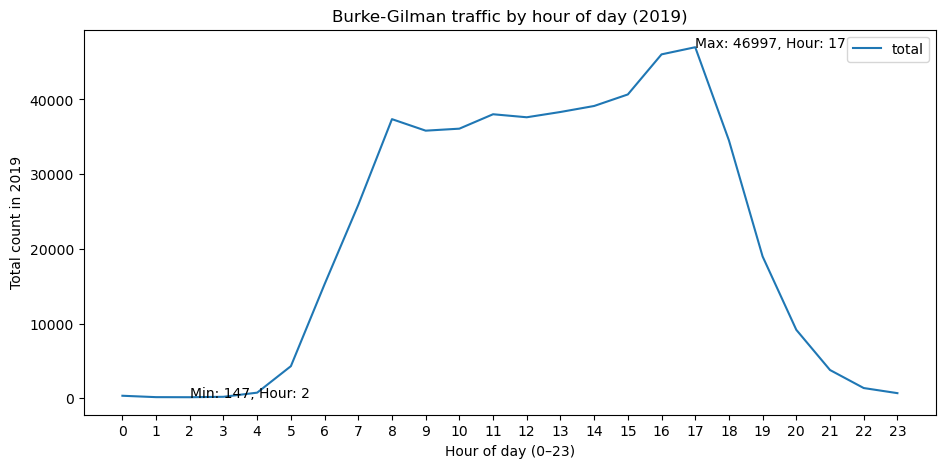

In [6]:
# Q1 Response
# Defining busy: Reported as single hours with bikes and peds together. 
# Justification: Single hours give a shorter and more specific time interval. 
# I consider bikes and peds together, as they contribute to the total volume of trail users.

# Combining bikes and peds as trail users
by_hour_all = pd.DataFrame({"total": by_hour["bikes"] + by_hour["peds"]})

# visualization (modified version of the previous plot)
by_hour_all.plot(figsize=(11, 5))
plt.title("Burke-Gilman traffic by hour of day (2019)")
plt.xlabel("Hour of day (0–23)")
plt.ylabel("Total count in 2019")
plt.xticks(range(0, 24))

# label max and min positions on the plot
x_max = by_hour_all.idxmax()
y_max = by_hour_all.max()
x_min = by_hour_all.idxmin()
y_min = by_hour_all.min()

plt.annotate(f"Max: " + str(y_max.iloc[0]) + ", Hour: " + str(x_max.iloc[0]), xy = (float(x_max.iloc[0]), float(y_max.iloc[0])))
plt.annotate(f"Min: " + str(y_min.iloc[0]) + ", Hour: " + str(x_min.iloc[0]), xy = (float(x_min.iloc[0]), float(y_min.iloc[0])))
plt.show()

**Your Q1 answer:**

Based on my visualization, the Burke-Gilman Trail is the busiest (has the most trail users, either peds or bikers) at 17:00 (5 PM) and the least busy at 2:00 AM. 

I defined "busy" as single hours counting bikes and peds together. Reasonably, most trail usage occurs during the day with little to no usage at night, so a large time interval that shows that the trail is busy during the day is not particularly interesting to me. Single hours provide a specific, short time interval. I considered bikes and peds together, as they contribute to the total volume of trail users.

*Gen AI Use Statement*: Claude Sonnet 5.5 Medium was used for understanding manipulation of pandas dataframes and annotating plots.

After searching Stack and other resources to find information about summing columns of a dataframe with no helpful information, I entered the following prompt in Claude: "how to sum with pandas and python two columns of a dataframe to create a new dataframe" and received general syntax for creating a new dataframe or creating a new column in the same dataframe. To create my `by_hour_all` dataframe, I referred to this line in Claude's output: `new_df = pd.DataFrame({"total": df["a"] + df["b"]})`. 

I also had difficulty finding relevant information for labeling the plot with maximum and minimum values, so I prompted "label max and min on the plt," and pasted the warning error when running the code cell: `Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  x = float(self.convert_xunits(x))`. 

Claude output did not resolve the warning, so I looked up the Series documentation and added `.iloc[0]` at the relevant locations to return scalar values and avoid the future variable-type error warning. 

Other resources:
- [pandas iloc and Series](https://pandas.pydata.org/docs/reference/api/pandas.Series.iloc.html)

**Q2. Do cyclists and pedestrians use the trail at different times of day?**
Compare their hourly patterns. If they differ, what might explain it?

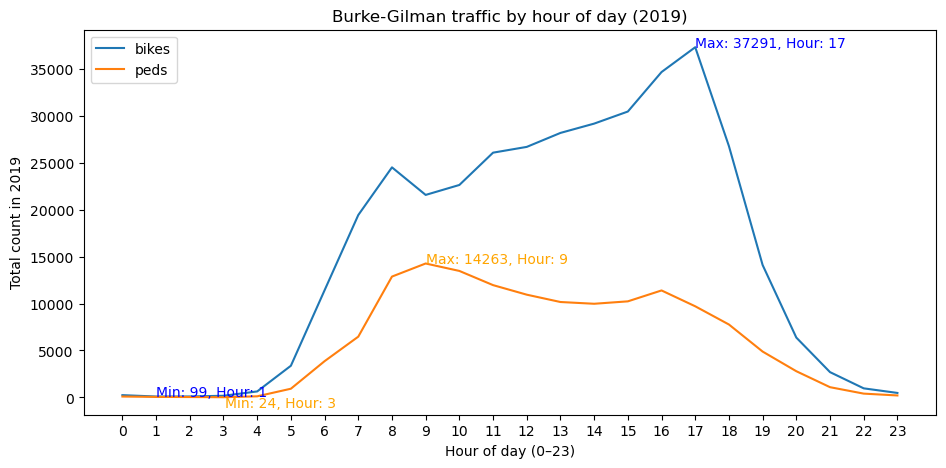

In [7]:
# graph cyclists and pedestrians, compare the min and max 
# previous graph code:
# group every row by its hour of day, and sum bikes and peds within each hour
by_hour = df.groupby("hour")[["bikes", "peds"]].sum()

by_hour.plot(figsize=(11, 5))
plt.title("Burke-Gilman traffic by hour of day (2019)")
plt.xlabel("Hour of day (0–23)")
plt.ylabel("Total count in 2019")
plt.xticks(range(0, 24))


#by_hour["bikes"].head()
# modified Q1 annotation code
x_max_bike = by_hour["bikes"].idxmax()
y_max_bike = by_hour["bikes"].max()
x_min_bike = by_hour["bikes"].idxmin()
y_min_bike = by_hour["bikes"].min()

x_max_peds = by_hour["peds"].idxmax()
y_max_peds = by_hour["peds"].max()
x_min_peds = by_hour["peds"].idxmin()
y_min_peds = by_hour["peds"].min()

plt.annotate(f"Max: {y_max_bike}, Hour: {int(x_max_bike)}", xy = (x_max_bike, y_max_bike), color="blue")
plt.annotate(f"Min: {y_min_bike}, Hour: {int(x_min_bike)}", xy = (x_min_bike, y_min_bike), color="blue")

plt.annotate(f"Max: {y_max_peds}, Hour: {int(x_max_peds)}", xy = (x_max_peds, y_max_peds), color="orange")
plt.annotate(f"Min: {y_min_peds}, Hour: {int(x_min_peds)}", xy = (x_min_peds, y_min_peds), xytext = (2, -10), textcoords = "offset pixels", color="orange")

plt.show()

**Your Q2 answer:**
Overall, more bikes have been counted than pedestrians. The number of bikes peaks in the afternoon at 17:00 (5:00 PM), while the number of pedestrians peaks in the morning at 9:00 AM. The minimums are at similar times, in the early morning before sunrise: 1 AM for bikes and 3 AM for pedestrians. There is a local maximum in the morning for bikes slightly earlier than the 9 AM peak for pedestrians.

Pedestrians may use different modes of transportation to return home after work, resulting in a smaller secondary peak in the afternoon when bike usage is highest. There may be more bikes than pedestrians using the trail overall because pedestrians are able to travel more freely off the trail, such as on sidewalks and near cars, while bikes prefer the level, safer trail that is not on the same road as cars. However, these assumptions cannot be tested with the available data.

*Generative AI Use Statement*: No new prompts since Q1.

**Q3. Commuting or recreation?**
Is there evidence people use the Burke-Gilman to *commute*, not just for fun? Compare **weekdays vs. weekends** (we made a `weekday` column for you), and maybe morning vs. evening. Define what a "commuting pattern" would look like in the data, then say whether you see it.

*Hint: `df.groupby("weekday")[["bikes","peds"]].sum()` gets you started. Weekends and weekdays will look different if commuting is real.*

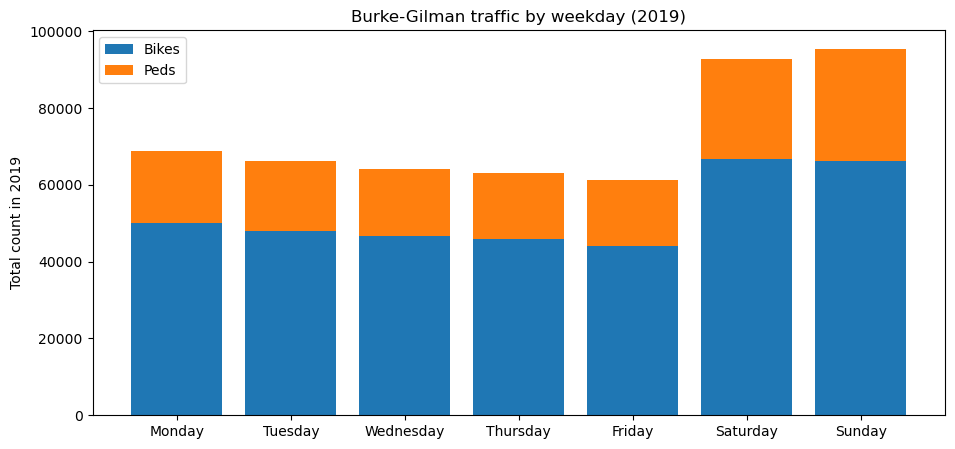

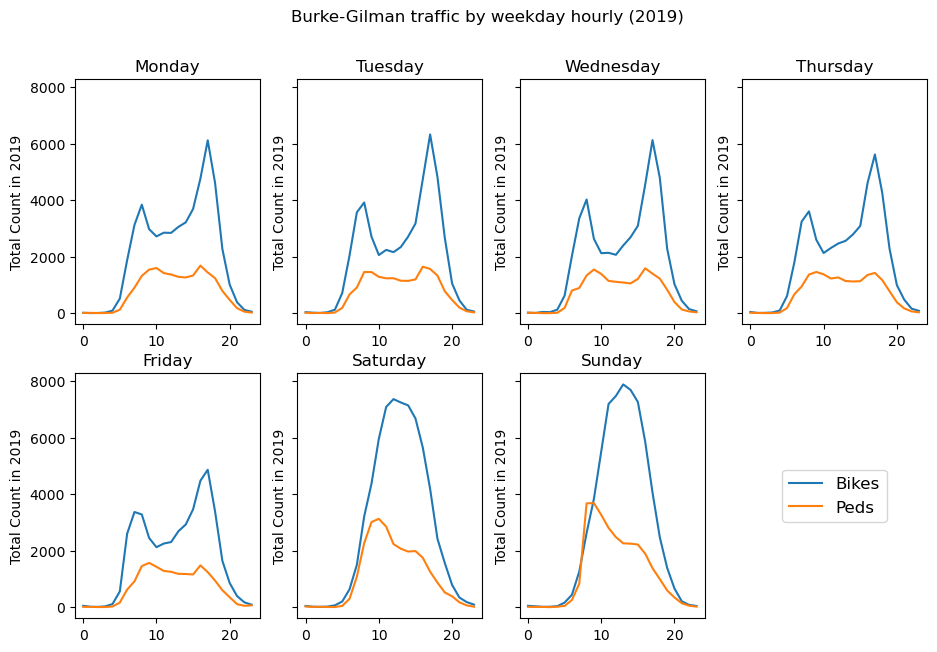

In [8]:
# Your code for Q3
by_week = df.groupby("weekday")[["bikes","peds"]].sum()


# Commute Pattern assumption 1: more traffic on weekdays

# Rearrange weekdays from Monday to Sunday, and plot bike and ped counts, maybe as a stacked bar chart to show total.

days_in_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_week = by_week.reindex(index=days_in_order)

# categories 
weekdays = by_week.index

# bikes and peds
bikes = by_week["bikes"]
peds = by_week["peds"]

# stacked bar chart
plt.figure(figsize=(11, 5))
plt.bar(weekdays, bikes)
plt.bar(weekdays, peds, bottom = bikes)
plt.title("Burke-Gilman traffic by weekday (2019)")
plt.ylabel("Total count in 2019")
plt.legend(["Bikes","Peds"])
plt.show()


# Commute Pattern assumption 2: consistent peak times on weekdays and varying peak times on weekends.

# make subset of data grouped by weekday with hours
by_week_hr = df[["weekday", "hour", "bikes", "peds"]]
by_week_hr = by_week_hr.groupby(["weekday","hour"])[["bikes","peds"]].sum()

# for each weekday, plots a line graph by hour per weekday

# Modified Claude output for a figure that has line plots hourly for each weekday 
fig, axes = plt.subplots(2, 4, figsize=(11,7), sharey=True)
axes = axes.flatten() # <- avoids numpynd array attribute error
for ax, day in zip(axes, days_in_order):
    # by day
    day_data = by_week_hr.loc[day] 

    ax.plot(day_data.index, day_data["bikes"], label = "Bikes")
    ax.plot(day_data.index, day_data["peds"], label = "Peds")
    ax.set_title(day)
    ax.set_ylabel("Total Count in 2019")

# The following 4 lines are pasted from Claude Sonnet 5.5: 
# Hide the unused 8th subplot and use it for the legend
axes[-1].axis("off")
handles, labels = axes[0].get_legend_handles_labels()
axes[-1].legend(handles, labels, loc="center", fontsize=12)
# end of pasted

plt.suptitle("Burke-Gilman traffic by weekday hourly (2019)")
plt.show()

**Your Q3 answer:**
I define a "commuting" pattern as potentially higher usage on weekdays, consistent peak times on weekdays, and less consistency on weekends. There is a noticeable pattern in the line charts showing consistent peaks on weekdays and a different pattern on weekends.

Based on the stacked bar chart visualization alone, there is no clear evidence of commuting, which I assumed would mean greater traffic on weekdays. Instead, traffic is noticeably higher on the weekend (Saturday and Sunday), likely due to increased recreational use.

To explore my other assumption of a commute pattern (consistent peak times during weekdays due to regular commuting times to and from work, and varying peak times during weekends), I would need to evaluate the peak hours per weekday. By plotting a line graph for each weekday similar to the first by-hour graph, my assumption that there would be a similar pattern during weekdays and a different pattern on weekends is visually obvious, providing evidence for commute patterns. The line plot shape for the weekdays is very similar, with consistent peaks in the morning and afternoon, and the shape for weekends is noticeably different.

*Gen AI Use Statement:* Claude Sonnet 5.5 Medium was used to inform the multi-day line-plot figure, as I had difficulty finding information on creating the figure. The following prompts were used:
- Given: "subset = df[["weekday", "hour", "bikes", "peds"]]
df is a pandas DataFrame. 
weekday are strings Monday, Tuesday, Wednesday, etc.
hour is int.
bikes are int (count of bikes)
peds are int (count of peds)." Note: I accidentally hit enter here, resulting in splitting my prompt into two prompts.
- "Plot a matplotlib line graph for each weekday where the x-axis is the hour from 0 to 23 and the y-axis is the total count split into two lines (one for bike, one for ped)" I intentionally did not provide Claude with the actual data or details of my code, variables, and setup so that I can use its output as a reference rather than just pasting it.
- "preview plot"
  
I used Claude's output as a reference, modifying as necessary. For example, Claude's output included a reindexing section that filled in missing hours and extra parameters. However, this is unnecessary since the dataset does not have any missing hours (0 to 23), so I removed that section of code and the sharex parameter. I also added a y-axis label to each line plot, adjusted the figure size, edited variables, and added a title.


Other sources referenced:
- [Geeks for Geeks - Stacked Bar Chart](https://www.geeksforgeeks.org/python/create-a-stacked-bar-plot-in-matplotlib/)
- [Pandas Reindex Usage](https://note.nkmk.me/en/python-pandas-reindex/#basic-usage-of-reindex)
- [Geeks for Geeks - Change Figure Size](https://www.geeksforgeeks.org/python/how-to-change-the-size-of-figures-drawn-with-matplotlib/)
- [Geeks for Geeks - groupby](https://www.geeksforgeeks.org/pandas/python-pandas-dataframe-groupby/)

**Q4. Direction and flow.**
The counter records **north vs. south** separately. Are mornings mostly one direction and evenings the other? What would that tell you about who's using the trail and where they're heading?

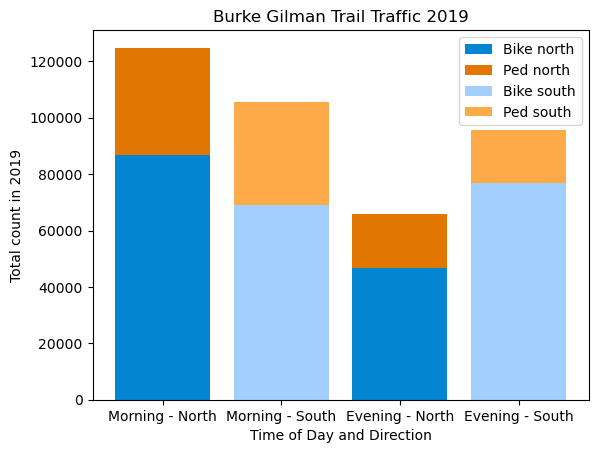

In [10]:
# Subset with north and south by hour
north_south_hr = df.groupby("hour")[["bike_north", "bike_south", "ped_north", "ped_south"]].sum()

# Adds the time of day to the given DataFrame `data` with information within the specified time range 
# (from int time1 to time2) 
def find_hr_data (data, time1, time2):
    time_of_day_list = []
    for i in data.index:
        if i >= time1 and i <= time2:
            time_of_day_list.append(data.iloc[i])
    return time_of_day_list
    
# Defining mornings as 5 AM to noon (12)
morn = find_hr_data(north_south_hr, 5, 12)
morning = pd.DataFrame(morn)

# Defining evenings as 4 PM to 11 PM (16 to 23)
eve = find_hr_data(north_south_hr, 16, 23)
evening = pd.DataFrame(eve)

# Compare counts of northbound and southbound peds and bikes; stacked bar chart categories are 
# north or south

# categories 
m = ["Morning - North"]
ms = ["Morning - South"]
y1 = morning["bike_north"].sum()
y2 = morning["ped_north"].sum()
y3 = morning["bike_south"].sum()
y4 = morning["ped_south"].sum()

e = ["Evening - North"]
es = ["Evening - South"]
x1 = evening["bike_north"].sum()
x2 = evening["ped_north"].sum()
x3 = evening["bike_south"].sum()
x4 = evening["ped_south"].sum()

plt.bar(m, y1, color='xkcd:cerulean')
plt.bar(m, y2, bottom=y1, color='xkcd:pumpkin')

plt.bar(ms, y3, color='xkcd:baby blue')
plt.bar(ms, y4, bottom=y3, color='xkcd:light orange')

plt.bar(e, x1, color='xkcd:cerulean')
plt.bar(e, x2, bottom=x1, color='xkcd:pumpkin')

plt.bar(es, x3, color='xkcd:baby blue')
plt.bar(es, x4, bottom=x3, color='xkcd:light orange')

plt.xlabel("Time of Day and Direction")
plt.ylabel("Total count in 2019")
plt.legend(["Bike north", "Ped north", "Bike south", "Ped south"])
plt.title("Burke Gilman Trail Traffic 2019")
plt.show()

**Your Q4 answer:**
Based on the stacked bar chart visualization, there is some potential evidence that mornings or evenings favor either direction because the count of northbound users is greater than that of southbound users in mornings and the count of southbound users is higher than that of northbound users in evenings. 

If mornings were mostly one direction and evenings the other, I would assume one direction in the morning has a higher count, then the opposite direction has a higher count in the evening (a symmetrical bar chart shape), and this appears to somewhat be the case, as the northbound users are greater in the morning and southbound users are greater in the evening. Mornings have a higher overall count of both northbound and southbound trail users than evenings, suggesting more traffic in the mornings and a northbound morning preference and less traffic in the evenings and a southbound evening preference, which is interesting because in previous visualization, the trail traffic peaks in the evening at 5 PM. This may be due to the sharp decrease in traffic (after 5 PM) included in the evening time range I chose.  

*Gen AI Use Statement*: No new prompts since Q3. 

Other resources:
- [Geeks for Geeks - Stacked Bar Chart](https://www.geeksforgeeks.org/python/create-a-stacked-bar-plot-in-matplotlib/)
- [Geeks for Geeks - Empty Data Frame](https://www.geeksforgeeks.org/python/how-to-add-empty-column-to-dataframe-in-pandas/)
- [Colors Matplotlib](https://matplotlib.org/stable/users/explain/colors/colors.html)
- This error I got when attempting to set values in the empty column:
"You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

`df["col"][row_indexer] = value`

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: [documentation](https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy)"

I changed my code to the specified format to 

## Part 3 — Make it reproducible

Good data work can be picked up and re-run by someone else. Two short deliverables:

**1. A `README.md`** in your `A1` folder. Use this template:

```
# A1 — Working with Open Data

**Dataset:** Burke-Gilman Trail counter north of NE 70th St
**Source:** https://data.seattle.gov/Transportation/.../2z5v-ecg8  (pulled YYYY-MM-DD)
**License / terms of use:** <find it on the dataset's page and note it here>

## Questions I asked
- ...

## How to re-run
Open `A1.ipynb` and run all cells (needs `requests`, `pandas`, `matplotlib`).
```

**2. A `LICENSE`** — keep the license file in this folder, and in your README **note the dataset's own license or terms of use** (open datasets almost always have one; find it on the dataset's page). Using open data responsibly means knowing what you're allowed to do with it — that's part of the assignment, not an afterthought.

### One more thing: read the data critically

In 3–4 sentences, name **one limitation or bias** in this dataset and how it could mislead someone who trusted it uncritically.

*(A sensor counts bodies, not intentions. It's one location on a long trail. Some hours may be missing when the counter was offline. A tandem bike counts once. What else?)* This is a warm-up for A2, where finding bias in data is the whole assignment.

**Your answer:**

The data does not differentiate between electric scooters, regular scooters, roller skates, skateboards, strollers, and other methods of travel on the trail besides bikes and pedestrians. Dogs and other animals might be present on the trail, but these are not counted in the dataset though they can contribute to traffic. If these other modes of travel are counted as bikes in the dataset, the count for bikes will be higher. 

Additionally, the data is focused on one location on a long trail; trail users who commute short distances that could contribute to possible commute patterns or other information are not included. 

Poor weather or other causes of sensor blockage can limit counts on days and times that do have poor weather or other conditions, which may result in lower counts of trail users. 

Large groups may be difficult to count accurately, resulting in possible lower counts, even though the presence of many large groups might be considered high traffic.

Furthermore, the intentions of trail users are not able to be captured by the sensor; with the commute patterns question, there may be users who travel along the trail not for commutes but for recreation, errands, or other purposes. Though patterns can be found through data visualizations, no definite evidence about user motivations such as commuting can be determined from the given dataset.

## Optional — going further

If you want to push further (not required for full credit):
- Which **day of the week** is busiest? Is it the same for bikes and pedestrians?
  - Based on the bar chart from the commute patternn question, Sunday is the busiest overall and for pedestrians. For bikes, Saturdays are slightly more busy. 
- Has the trail gotten **busier over time**? (the data goes back to 2014 — change the year in the query)
- Do fewer people ride when it's **cold or wet**? (join with a Seattle [weather dataset](https://data.seattle.gov/))
- Compare with another counter — the [Fremont Bridge](https://data.seattle.gov/Transportation/Fremont-Bridge-Bicycle-Counter/65db-xm6k) or the [MTS Trail](https://data.seattle.gov/Transportation/MTS-Trail-west-of-I-90-Bridge-Bicycle-and-Pedestri/u38e-ybnc).

## A note on using AI

You may use an LLM (ChatGPT, Claude, …) to help you write code or make a plot. Treat it as a **tool you supervise, not an author you trust**:
- paste the **prompt** you used into a Markdown cell,
- **run** the output and check it against what you expected,
- note **what you changed and why**.

Here, AI is your assistant. In **A3** it becomes your subject of study. Code that runs but that you can't explain won't earn credit — the point is that *you* can ask a question of data and defend the answer.